In [0]:
# Part 1 – Data Loading & Train-Test Split 
# Notebook 14 – Machine Learning Model Comparison

#Objective

# Compare multiple Machine Learning models for customer churn prediction.

# Models

# - Decision Tree
# - Random Forest
# - Logistic Regression

# Evaluation Metrics

# - Accuracy
# - Precision
# - Recall
# - F1 Score

# Output

# model_comparison_results

In [0]:
# Import Libraries 
from pyspark.sql.functions import *

from pyspark.ml.classification import (
    DecisionTreeClassifier,
    RandomForestClassifier,
    LogisticRegression
)

from pyspark.ml.evaluation import MulticlassClassificationEvaluator

from pyspark.sql import Row

import pandas as pd

In [0]:
# Load ML Dataset 
ml_data = spark.table("customer_churn_ml_dataset")

display(ml_data.limit(5))

CustomerID,scaled_features,Churn
100030,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}",0
100036,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}",0
100042,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}",0
100043,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.5714469091134694"",""0.5017037789362383"",""-0.5912320345914457"",""0.0"",""-0.4484382496396012"",""-0.6976644474584527"",""-0.6542564223713676"",""-0.3646982166904183"",""-0.20528502621170325"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.6653263340107006"",""-0.35087869992540816"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.4510289960825741"",""-0.6070927175107699"",""0.5017037789362383""]}",0
100060,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6270066423868055"",""-1.4665176541698055"",""1.0250281728877428"",""0.0"",""0.008208379665322391"",""0.8888830904649767"",""1.546248748766258"",""0.9874235260366689"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""2.5985000807153225"",""0.21640979219593814"",""-0.5681575624813238"",""-0.34133703226515455"",""1.1890099280292505"",""1.0672193128192116"",""-1.4665176541698055""]}",0


In [0]:
# Check Schema 
ml_data.printSchema()

root
 |-- CustomerID: long (nullable = true)
 |-- scaled_features: vectorudt (nullable = true)
 |-- Churn: integer (nullable = true)



In [0]:
# Count Records 
print("Total Records :", ml_data.count())

Total Records : 286893


In [0]:
# Check Class Distribution 
display(

ml_data.groupBy("Churn")

.count()

.orderBy("Churn")

)

Churn,count
0,235541
1,51352


In [0]:
# Train/Test Split 
train_data, test_data = ml_data.randomSplit(

[0.8,0.2],

seed=42

)

In [0]:
# Verify Split 
print("Training Records :", train_data.count())

print("Testing Records :", test_data.count())

Training Records : 229716
Testing Records : 57177


In [0]:
# Verify Dataset 
display(train_data.limit(5))

CustomerID,scaled_features,Churn
100000,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.893329653831311"",""1.4217086917701374"",""-1.2541292901082717"",""0.0"",""1.8347948968850167"",""1.4936995551982177"",""-0.07362034286374262"",""1.1550866221348277"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.9979705129695879"",""-0.915346125668659"",""-0.932904051073773"",""-1.4955190158535085"",""1.1271668934749024"",""-1.2126088398394"",""1.4217086917701374""]}",0
100000,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.893329653831311"",""1.4217086917701374"",""-0.654034648878629"",""0.0"",""1.8347948968850167"",""1.4936995551982177"",""-0.07362034286374262"",""1.1550866221348277"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.814037849309968"",""-0.7684600614145789"",""-0.932904051073773"",""-1.4955190158535085"",""1.1271668934749024"",""-0.6129265171661069"",""1.4217086917701374""]}",0
100000,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.893329653831311"",""1.4217086917701374"",""-0.5383283167970341"",""0.0"",""1.8347948968850167"",""1.4936995551982177"",""-0.07362034286374262"",""1.1550866221348277"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.7788167009496152"",""-0.7401477375839629"",""-0.932904051073773"",""-1.4955190158535085"",""1.1271668934749024"",""-0.4972996856574658"",""1.4217086917701374""]}",0
100000,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.893329653831311"",""1.4217086917701374"",""-0.5034225926258438"",""0.0"",""1.8347948968850167"",""1.4936995551982177"",""-0.07362034286374262"",""1.1550866221348277"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.767076318162831"",""-0.731595585906223"",""-0.932904051073773"",""-1.4955190158535085"",""1.1271668934749024"",""-0.462412180208752"",""1.4217086917701374""]}",0
100000,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.893329653831311"",""1.4217086917701374"",""1.9894610446459262"",""0.0"",""1.8347948968850167"",""1.4936995551982177"",""-0.07362034286374262"",""1.1550866221348277"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""0.003875484836001891"",""-0.12143196784030831"",""-0.932904051073773"",""-1.4955190158535085"",""1.1271668934749024"",""2.028758623600014"",""1.4217086917701374""]}",0


In [0]:
# Verify Test Dataset 
display(test_data.limit(5))

CustomerID,scaled_features,Churn
100002,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.3593949238591958"",""-0.5378497948873764"",""-0.5025399987077821"",""0.0"",""-0.9050848789445248"",""-0.6012444313415591"",""0.5429096033770815"",""0.20319291525495833"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.30137446762038883"",""-0.04442448022202598"",""0.8908283918884737"",""-0.34133703226515455"",""0.27606611301893647"",""-0.4922383456402862"",""-0.5378497948873764""]}",0
100003,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.3717046505300903"",""0.2106287782656262"",""0.39542143698617666"",""0.0"",""-1.3617315082494486"",""-0.7064299034690794"",""2.0631204297243184"",""-0.08886538117409251"",""-0.26022270241941475"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.15266295232112148"",""1.45985198211946"",""-0.932904051073773"",""-1.4955190158535085"",""0.20143898863423174"",""0.4024197955740962"",""0.2106287782656262""]}",0
100004,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.3051238976689639"",""0.22968726045239246"",""-0.257507698985481"",""0.0"",""0.464855008970246"",""0.1394366015563954"",""-0.36288268065481366"",""0.34922206346948376"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""-0.45791290477751223"",""-0.46968117546060967"",""-0.6228695357701911"",""-0.34133703226515455"",""0.29284523092127873"",""-0.24676911943124455"",""0.22968726045239246""]}",0
100008,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.4259756767203222"",""1.0336086908759878"",""-0.7789188039905273"",""0.0"",""0.008208379665322391"",""0.13505387355108206"",""0.23886743810763408"",""0.7764925341712433"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""-0.814037849309968"",""-0.5783684760545319"",""-0.5681575624813238"",""-0.34133703226515455"",""0.7979765803432295"",""-0.7496057561266154"",""1.0336086908759878""]}",0
100008,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.4259756767203222"",""1.0336086908759878"",""-0.36165954990447574"",""0.0"",""0.008208379665322391"",""0.13505387355108206"",""0.23886743810763408"",""0.7764925341712433"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""-0.6692397949396288"",""-0.3945289837486424"",""-0.5681575624813238"",""-0.34133703226515455"",""0.7979765803432295"",""-0.3326274317500052"",""1.0336086908759878""]}",0


In [0]:
# Create Evaluator 
evaluator = MulticlassClassificationEvaluator(

labelCol="Churn",

predictionCol="prediction",

metricName="accuracy"

)

In [0]:
# Part 1: Data Preparation and Model Initialization
# Objective

# The objective of Part 1 is to prepare the machine learning dataset before training the classification models. This stage ensures that the data is correctly loaded, validated, and divided into training and testing datasets for unbiased model evaluation.

# Activities Performed
# Imported the required PySpark Machine Learning libraries.
# Loaded the final machine learning dataset (customer_churn_ml_dataset) containing customer features and the target variable (Churn).
# Verified the dataset structure and data types to ensure the input data was suitable for machine learning.
# Performed Exploratory Data Analysis (EDA) by checking the total number of records and the distribution of the target variable (Churn).
# Split the dataset into 80% training data and 20% testing data using a fixed random seed to ensure reproducibility.
# Created a model evaluator that will later be used to calculate the performance metrics of all classification models.
# Output

# At the end of Part 1, the following datasets and objects were successfully created:

# ML Dataset
# Training Dataset (80%)
# Testing Dataset (20%)
# Model Evaluation Object
# Business Purpose

# This stage establishes a reliable foundation for machine learning by ensuring that all models are trained on the same training dataset and evaluated on the same testing dataset. Using a consistent train-test split enables a fair comparison of multiple classification algorithms and helps identify the most suitable model for customer churn prediction.


In [0]:
# Part 1 prepares the customer churn dataset for machine learning by loading the data, validating its structure, analysing the target distribution, splitting it into training and testing datasets, and creating the evaluation framework for model comparison.

In [0]:
# Part 2 
# Train Decision Tree Model

In [0]:
# Decision Tree Accuracy:
# The Decision Tree classifier achieved an accuracy of 82.17%, indicating that the model correctly classified approximately 82% of the customer records in the testing dataset. The bar chart visually represents the overall prediction accuracy, making it easier to compare with the other machine learning models (Random Forest and Logistic Regression) that will be evaluated later in the notebook.

In [0]:
# Train Decision Tree Model 
from pyspark.ml.classification import DecisionTreeClassifier

# Create Decision Tree Model
dt = DecisionTreeClassifier(
    featuresCol="scaled_features",
    labelCol="Churn",
    maxDepth=5,
    seed=42
)

# Train Model
dt_model = dt.fit(train_data)

print("Decision Tree Model Trained Successfully")

Decision Tree Model Trained Successfully


In [0]:
# Make Predictions 
# Predict Test Dataset

dt_predictions = dt_model.transform(test_data)

display(
    dt_predictions.select(
        "CustomerID",
        "Churn",
        "prediction",
        "probability"
    )
)

CustomerID,Churn,prediction,probability
100002,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8265046976843106"",""0.17349530231568938""]}"
100003,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8207580962925575"",""0.17924190370744256""]}"
100004,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8207580962925575"",""0.17924190370744256""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8008583044722181"",""0.19914169552778196""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8008583044722181"",""0.19914169552778196""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8008583044722181"",""0.19914169552778196""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8008583044722181"",""0.19914169552778196""]}"
100009,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8207580962925575"",""0.17924190370744256""]}"
100010,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8207580962925575"",""0.17924190370744256""]}"
100013,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8265046976843106"",""0.17349530231568938""]}"


In [0]:
# Evaluate All Metrics 
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metrics = [
    ("Accuracy", "accuracy"),
    ("Precision", "weightedPrecision"),
    ("Recall", "weightedRecall"),
    ("F1 Score", "f1")
]

results = []

for metric_name, metric in metrics:

    evaluator = MulticlassClassificationEvaluator(
        labelCol="Churn",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(dt_predictions)

    results.append((metric_name, float(score)))

evaluation_df = spark.createDataFrame(
    results,
    ["Metric", "Score"]
)

display(evaluation_df)

Metric,Score
Accuracy,0.8217814855623765
Precision,0.8040500119396264
Recall,0.8217814855623765
F1 Score,0.7416971057585424


In [0]:
# Convert to Pandas 
evaluation_pd = evaluation_df.toPandas()

evaluation_pd

,Metric,Score
0,Accuracy,0.821781
1,Precision,0.804050
2,Recall,0.821781
3,F1 Score,0.741697


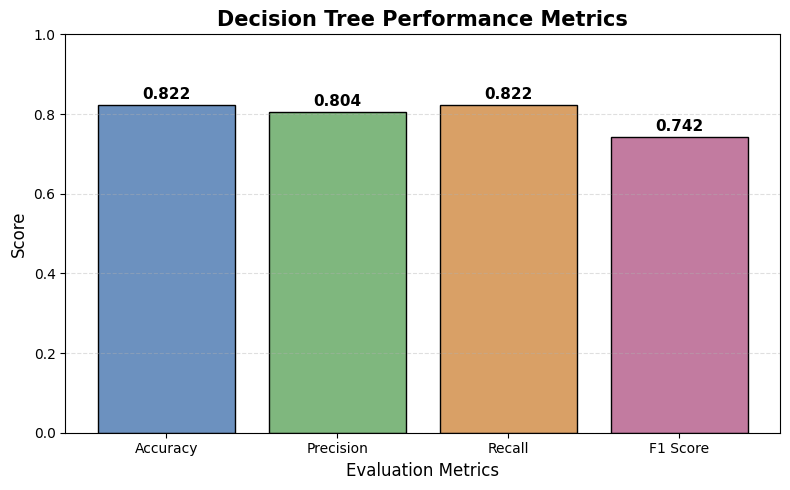

In [0]:
import matplotlib.pyplot as plt

colors = [
    "#6C91BF",   # Muted Blue
    "#7FB77E",   # Muted Green
    "#D9A066",   # Muted Orange
    "#C27BA0"    # Muted Purple
]

plt.figure(figsize=(8,5))

bars = plt.bar(
    evaluation_pd["Metric"],
    evaluation_pd["Score"],
    color=colors,
    edgecolor="black",
    linewidth=1
)

plt.ylim(0,1)

plt.title(
    "Decision Tree Performance Metrics",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Evaluation Metrics", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.4)

# Add values on top of each bar
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.015,
        f"{height:.3f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()

In [0]:
# Feature Importance

feature_importance = dt_model.featureImportances

print(feature_importance)

(18,[0,1,4,6,8,9,14,15],[0.2079904000918269,0.19169348185267016,0.0450042327921015,0.08992510213549672,0.01943744229891774,0.06464711369931073,0.18199163248465042,0.1993105946450259])


In [0]:
# Save Metrics 
decision_tree_results = spark.createDataFrame(
    [
        (
            "Decision Tree",
            float(evaluation_pd.iloc[0]["Score"]),
            float(evaluation_pd.iloc[1]["Score"]),
            float(evaluation_pd.iloc[2]["Score"]),
            float(evaluation_pd.iloc[3]["Score"])
        )
    ],
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score"
    ]
)

display(decision_tree_results)

Model,Accuracy,Precision,Recall,F1_Score
Decision Tree,0.8217814855623765,0.8040500119396264,0.8217814855623765,0.7416971057585424


In [0]:
# Part 2 Summary

# Completed Tasks

# - Decision Tree Model Training
# - Prediction Generation
# - Accuracy Calculation
# - Precision Calculation
# - Recall Calculation
# - F1 Score Calculation
# - Performance Visualization
# - Feature Importance Analysis

# Output

# decision_tree_results

In [0]:
# In this part, a Decision Tree classification model was trained using the prepared customer churn dataset. The trained model generated predictions for the testing dataset, and its performance was evaluated using four classification metrics: Accuracy, Precision, Recall, and F1 Score. The evaluation results were displayed in both tabular and graphical formats to facilitate interpretation. Additionally, feature importance values were extracted from the trained model to identify the variables that contributed most to churn prediction.

In [0]:
# Part 3
# Random Forest Model 
# Train Random Forest Model 

from pyspark.ml.classification import RandomForestClassifier

# Create Random Forest Model
rf = RandomForestClassifier(
    featuresCol="scaled_features",
    labelCol="Churn",
    numTrees=50,
    maxDepth=10,
    seed=42
)

# Train Model
rf_model = rf.fit(train_data)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [0]:
# Predict Test Dataset 
# Generate Predictions

rf_predictions = rf_model.transform(test_data)

display(
    rf_predictions.select(
        "CustomerID",
        "Churn",
        "prediction",
        "probability"
    )
)

CustomerID,Churn,prediction,probability
100002,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8216043518203402"",""0.17839564817965978""]}"
100003,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8383935422976898"",""0.16160645770231014""]}"
100004,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8193570246425829"",""0.18064297535741708""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8311356967205814"",""0.16886430327941865""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8295571328212878"",""0.1704428671787121""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8273766018523981"",""0.17262339814760186""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8273766018523981"",""0.17262339814760186""]}"
100009,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8148014534191674"",""0.18519854658083257""]}"
100010,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8203810100553282"",""0.17961898994467182""]}"
100013,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8157218630343449"",""0.1842781369656551""]}"


In [0]:
# Evaluate Random Forest Model 
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metrics = [
    ("Accuracy", "accuracy"),
    ("Precision", "weightedPrecision"),
    ("Recall", "weightedRecall"),
    ("F1 Score", "f1")
]

rf_results = []

for metric_name, metric in metrics:

    evaluator = MulticlassClassificationEvaluator(
        labelCol="Churn",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(rf_predictions)

    rf_results.append((metric_name, float(score)))

rf_metrics = spark.createDataFrame(
    rf_results,
    ["Metric", "Score"]
)

display(rf_metrics)

Metric,Score
Accuracy,0.8217465064623887
Precision,0.8535241490807675
Recall,0.8217465064623888
F1 Score,0.7414464151904006


In [0]:
# Convert to Pandas 
rf_metrics_pd = rf_metrics.toPandas()

rf_metrics_pd

,Metric,Score
0,Accuracy,0.821747
1,Precision,0.853524
2,Recall,0.821747
3,F1 Score,0.741446


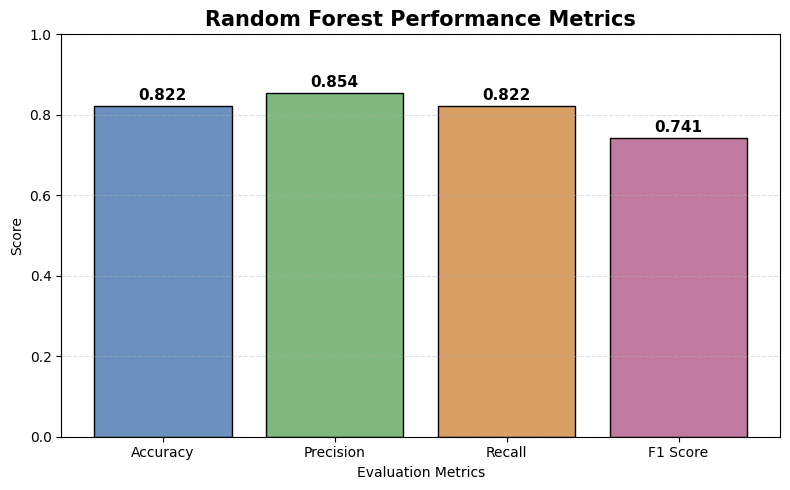

In [0]:
# Random Forest Performance Graph 
import matplotlib.pyplot as plt

colors = [
    "#6C91BF",
    "#7FB77E",
    "#D9A066",
    "#C27BA0"
]

plt.figure(figsize=(8,5))

bars = plt.bar(
    rf_metrics_pd["Metric"],
    rf_metrics_pd["Score"],
    color=colors,
    edgecolor="black"
)

plt.ylim(0,1)

plt.title(
    "Random Forest Performance Metrics",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Evaluation Metrics")

plt.ylabel("Score")

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height+0.015,
        f"{height:.3f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()

In [0]:
# Feature Importance 
rf_feature_importance = rf_model.featureImportances

print(rf_feature_importance)

(18,[0,1,2,4,5,6,7,8,9,10,11,12,13,14,15,16,17],[0.11826751099789473,0.07699531409108125,0.03115387840554137,0.044780261596355994,0.08690118334089564,0.0946555521654516,0.07936303979896808,0.03283194354298189,0.03463339435255555,0.04736691673081836,0.038405624657466504,0.036184775274999914,0.059033368008609616,0.040695406153214125,0.0831370126009911,0.03261801747881135,0.0629768008033629])


In [0]:
# Save Random Forest Results 
random_forest_results = spark.createDataFrame(
    [
        (
            "Random Forest",
            float(rf_metrics_pd.iloc[0]["Score"]),
            float(rf_metrics_pd.iloc[1]["Score"]),
            float(rf_metrics_pd.iloc[2]["Score"]),
            float(rf_metrics_pd.iloc[3]["Score"])
        )
    ],
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score"
    ]
)

display(random_forest_results)

Model,Accuracy,Precision,Recall,F1_Score
Random Forest,0.8217465064623887,0.8535241490807675,0.8217465064623888,0.7414464151904006


In [0]:
# # Part 3 Summary

## Completed Tasks

# - Random Forest Model Training
# - Prediction Generation
# - Accuracy Calculation
# - Precision Calculation
# - Recall Calculation
# - F1 Score Calculation
# - Performance Visualization
# - Feature Importance Analysis

# Output

# random_forest_results 

# In this part, a Random Forest classification model was trained using the prepared customer churn dataset. The Random Forest algorithm combines multiple decision trees to improve prediction accuracy and reduce overfitting. The trained model was evaluated using Accuracy, Precision, Recall, and F1 Score. The evaluation results were presented in both tabular and graphical formats. In addition, feature importance scores were extracted to identify the most influential variables contributing to customer churn prediction.

In [0]:
# Part 4
# Logistic Regression Model
# Train Logistic Regression Model 

from pyspark.ml.classification import LogisticRegression

# Create Logistic Regression Model
lr = LogisticRegression(
    featuresCol="scaled_features",
    labelCol="Churn",
    maxIter=100,
    regParam=0.01,
    elasticNetParam=0.0
)

# Train Model
lr_model = lr.fit(train_data)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


In [0]:
# Generate Predictions 
# Predict Test Dataset

lr_predictions = lr_model.transform(test_data)

display(
    lr_predictions.select(
        "CustomerID",
        "Churn",
        "prediction",
        "probability"
    )
)

CustomerID,Churn,prediction,probability
100002,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8226984310377454"",""0.17730156896225457""]}"
100003,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8212202424260299"",""0.17877975757397013""]}"
100004,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8185725853529523"",""0.1814274146470477""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8173669095568511"",""0.1826330904431489""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8172382191143085"",""0.1827617808856915""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8170728723290602"",""0.18292712767093977""]}"
100008,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8170661872542253"",""0.1829338127457747""]}"
100009,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8165498919191654"",""0.18345010808083462""]}"
100010,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8218516514614262"",""0.17814834853857375""]}"
100013,0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8272523385419471"",""0.17274766145805287""]}"


In [0]:
# Evaluate Logistic Regression Model 
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metrics = [
    ("Accuracy", "accuracy"),
    ("Precision", "weightedPrecision"),
    ("Recall", "weightedRecall"),
    ("F1 Score", "f1")
]

lr_results = []

for metric_name, metric in metrics:

    evaluator = MulticlassClassificationEvaluator(
        labelCol="Churn",
        predictionCol="prediction",
        metricName=metric
    )

    score = evaluator.evaluate(lr_predictions)

    lr_results.append((metric_name, float(score)))

lr_metrics = spark.createDataFrame(
    lr_results,
    ["Metric", "Score"]
)

display(lr_metrics)

Metric,Score
Accuracy,0.8216415691624255
Precision,0.6750948681756928
Recall,0.8216415691624255
F1 Score,0.7411939643934403


In [0]:
# Convert to Pandas 
lr_metrics_pd = lr_metrics.toPandas()

lr_metrics_pd

,Metric,Score
0,Accuracy,0.821642
1,Precision,0.675095
2,Recall,0.821642
3,F1 Score,0.741194


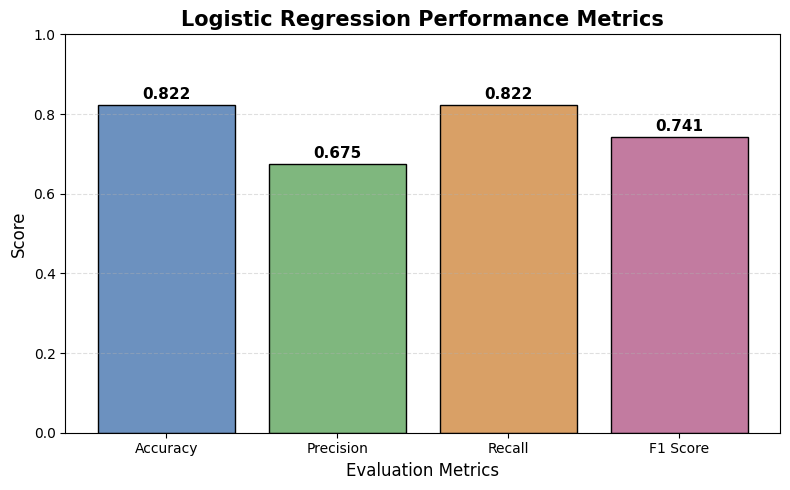

In [0]:
# Logistic Regression Performance Graph 
import matplotlib.pyplot as plt

colors = [
    "#6C91BF",   # Muted Blue
    "#7FB77E",   # Muted Green
    "#D9A066",   # Muted Orange
    "#C27BA0"    # Muted Purple
]

plt.figure(figsize=(8,5))

bars = plt.bar(
    lr_metrics_pd["Metric"],
    lr_metrics_pd["Score"],
    color=colors,
    edgecolor="black",
    linewidth=1
)

plt.ylim(0,1)

plt.title(
    "Logistic Regression Performance Metrics",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Evaluation Metrics", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        height+0.015,
        f"{height:.3f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()

In [0]:
# Save Logistic Regression Results 
logistic_results = spark.createDataFrame(
    [
        (
            "Logistic Regression",
            float(lr_metrics_pd.iloc[0]["Score"]),
            float(lr_metrics_pd.iloc[1]["Score"]),
            float(lr_metrics_pd.iloc[2]["Score"]),
            float(lr_metrics_pd.iloc[3]["Score"])
        )
    ],
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score"
    ]
)

display(logistic_results)

Model,Accuracy,Precision,Recall,F1_Score
Logistic Regression,0.8216415691624255,0.6750948681756928,0.8216415691624255,0.7411939643934403


In [0]:
# # Part 4 Summary

#Completed Tasks

# - Logistic Regression Model Training
# - Prediction Generation
# - Accuracy Calculation
# - Precision Calculation
# - Recall Calculation
# - F1 Score Calculation
# - Performance Visualization

# Output

# logistic_results 

# In this section, a Logistic Regression classifier was trained using the prepared customer churn dataset. Logistic Regression estimates the probability of customer churn by modelling the relationship between the input features and the target variable. The trained model was evaluated using Accuracy, Precision, Recall, and F1 Score. The results were presented in both tabular and graphical formats to enable comparison with the Decision Tree and Random Forest models.

In [0]:
# Part 5
# Model Comparison & Save Results

# Combine all model results

model_comparison = decision_tree_results.union(random_forest_results)

model_comparison = model_comparison.union(logistic_results)

display(model_comparison)

Model,Accuracy,Precision,Recall,F1_Score
Decision Tree,0.8217814855623765,0.8040500119396264,0.8217814855623765,0.7416971057585424
Random Forest,0.8217465064623887,0.8535241490807675,0.8217465064623888,0.7414464151904006
Logistic Regression,0.8216415691624255,0.6750948681756928,0.8216415691624255,0.7411939643934403


In [0]:
# Convert to Pandas 
comparison_pd = model_comparison.toPandas()

comparison_pd

,Model,Accuracy,Precision,Recall,F1_Score
0,Decision Tree,0.821781,0.804050,0.821781,0.741697
1,Random Forest,0.821747,0.853524,0.821747,0.741446
2,Logistic Regression,0.821642,0.675095,0.821642,0.741194


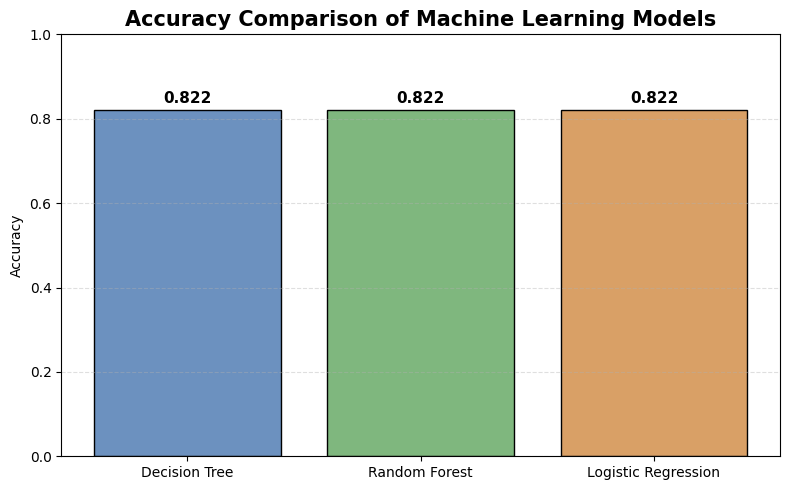

In [0]:
# Accuracy Comparison Graph 
import matplotlib.pyplot as plt

colors = ["#6C91BF", "#7FB77E", "#D9A066"]

plt.figure(figsize=(8,5))

bars = plt.bar(
    comparison_pd["Model"],
    comparison_pd["Accuracy"],
    color=colors,
    edgecolor="black"
)

plt.title(
    "Accuracy Comparison of Machine Learning Models",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Accuracy")

plt.ylim(0,1)

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:

    y = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        y+0.015,
        f"{y:.3f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()

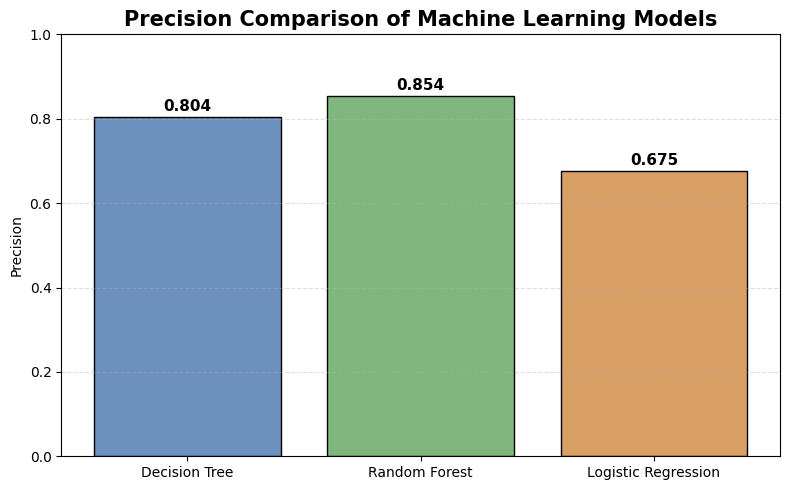

In [0]:
# Precision Comparison Graph 
plt.figure(figsize=(8,5))

bars = plt.bar(
    comparison_pd["Model"],
    comparison_pd["Precision"],
    color=colors,
    edgecolor="black"
)

plt.title(
    "Precision Comparison of Machine Learning Models",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Precision")

plt.ylim(0,1)

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:

    y = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        y+0.015,
        f"{y:.3f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()

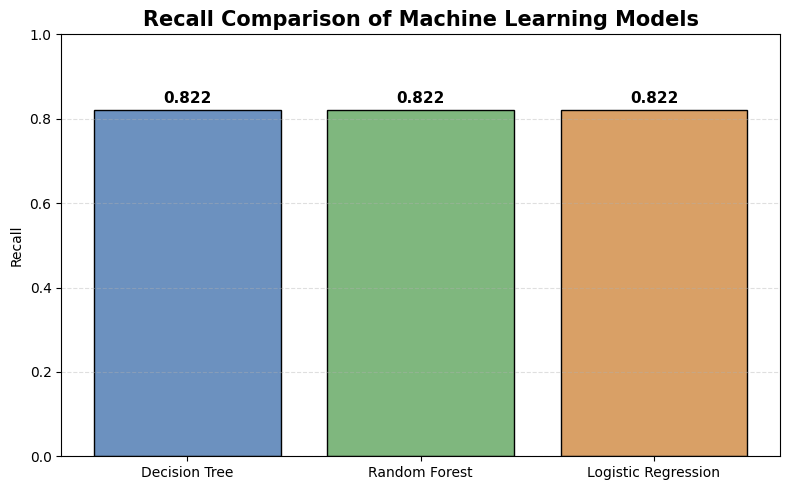

In [0]:
# Recall Comparison Graph 
plt.figure(figsize=(8,5))

bars = plt.bar(
    comparison_pd["Model"],
    comparison_pd["Recall"],
    color=colors,
    edgecolor="black"
)

plt.title(
    "Recall Comparison of Machine Learning Models",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Recall")

plt.ylim(0,1)

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:

    y = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        y+0.015,
        f"{y:.3f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()

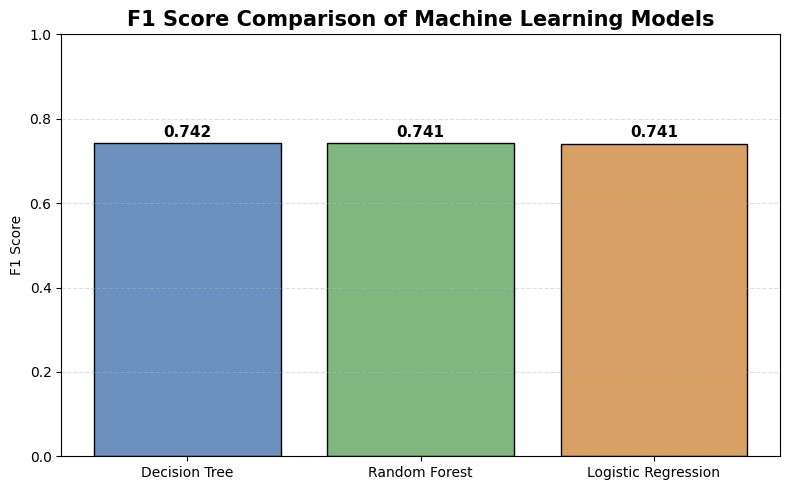

In [0]:
# F1 Score Comparison Graph 
plt.figure(figsize=(8,5))

bars = plt.bar(
    comparison_pd["Model"],
    comparison_pd["F1_Score"],
    color=colors,
    edgecolor="black"
)

plt.title(
    "F1 Score Comparison of Machine Learning Models",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("F1 Score")

plt.ylim(0,1)

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:

    y = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        y+0.015,
        f"{y:.3f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()

plt.show()

In [0]:
# Save Model Comparison Results

# To avoid issues with column names, rename F1_Score before saving: 
model_comparison_save = model_comparison.withColumnRenamed(
    "F1_Score",
    "F1Score"
)

model_comparison_save.write \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable("model_comparison_results")

print("✅ Model comparison results saved successfully.")

✅ Model comparison results saved successfully.


In [0]:
# Verify Saved Table 
display(
    spark.table("model_comparison_results")
)

Model,Accuracy,Precision,Recall,F1Score
Decision Tree,0.8217814855623765,0.8040500119396264,0.8217814855623765,0.7416971057585424
Random Forest,0.8217465064623887,0.8535241490807675,0.8217465064623888,0.7414464151904006
Logistic Regression,0.8216415691624255,0.6750948681756928,0.8216415691624255,0.7411939643934403


In [0]:
# Identify the Best Model 
best_model = comparison_pd.sort_values(
    by="Accuracy",
    ascending=False
)

best_model.head(1)

,Model,Accuracy,Precision,Recall,F1_Score
0,Decision Tree,0.821781,0.80405,0.821781,0.741697


In [0]:
# Notebook 14 Summary

# Objective

# To compare the performance of multiple Machine Learning algorithms for customer churn prediction.

# Models Evaluated

# - Decision Tree
# - Random Forest
# - Logistic Regression

#  Evaluation Metrics

# - Accuracy
# - Precision
# - Recall
# - F1 Score

# Output

# - model_comparison_results

# Conclusion

# All three machine learning models were successfully trained and evaluated using the same dataset. Their performance was compared using four standard evaluation metrics. The results were saved to the `model_comparison_results` table for reporting and visualization.